# Лабораторная работа 3. Граничные условия

$$u_t=(\lambda u_x)_x-vu_x-\sigma u+f,\qquad x,t\in[0,1].$$

На фотографии нет численного варианта, поэтому выбрана проверочная модель:
$\lambda=1+x$, $v=\sigma=1$, $u_*=e^{-t}(1+x+x^2)$,
$u_0=1+x+x^2$, $f=-2(1+x)e^{-t}$.

Все три типа условий проверяются на одном решении:

- Дирихле: $u(0,t)=e^{-t}$, $u(1,t)=3e^{-t}$.
- Неймана: $u_x(0,t)=e^{-t}$, $u_x(1,t)=3e^{-t}$.
- Робина: $-\lambda u_x(0,t)+u(0,t)=0$, $\lambda u_x(1,t)+u(1,t)=9e^{-t}$.

[Полная постановка и знаки коэффициентов](README.md) · [Фото задания](materials/laba3.jpeg)


## Параметры модельной задачи


In [1]:
%matplotlib inline
# Лабораторная 3. Граничные условия I, II, III рода.
# u_t=((1+x)*u_x)_x-u_x-u+f; x,t ∈ [0,1].
# Модель: u=exp(-t)*(1+x+x²), f=-2*(1+x)*exp(-t).
# Неявная схема, перенос против потока (v=1), прогонка без своих функций.
# Границы с фото: -κ₁λu_x=α₁u+ν₁μ₁; κ₂λu_x=α₂u+ν₂μ₂.

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
out = root/'results'; out.mkdir(parents=True,exist_ok=True)
L, T, v, sigma = 1., 1., 1., 1.
meshes = [10,20,40,80]; names = ['Дирихле','Неймана','Робина']
convergence, table, solutions = [], [], []



## Неявная схема, прогонка и проверки

Сетки N=10, 20, 40, 80; τ=h². Ожидаемый порядок O(τ+h).


In [2]:
for kind, name in enumerate(names,1):
    # Одинаковые коэффициенты слева и справа; α=-1 для диссипативного Робина.
    kappa, boundary_alpha, nu = [(0.,-1.,1.),(1.,0.,-1.),(1.,-1.,-1.)][kind-1]
    folder = out/f'type{kind}'; folder.mkdir(exist_ok=True); previous_error = None
    for N in meshes:
        M = N*N; h = L/N; tau = T/M
        x = np.linspace(0,L,N+1); t = np.linspace(0,T,M+1)
        lam_half = 1+(x[:-1]+x[1:])/2
        u = np.zeros((M+1,N+1)); u[0] = 1+x+x*x
        exact = np.exp(-t[:,None])*(1+x+x*x)
        if kind == 1: mu1, mu2 = np.exp(-t), 3*np.exp(-t)
        elif kind == 2: mu1, mu2 = np.exp(-t), -6*np.exp(-t)
        else: mu1, mu2 = np.zeros(M+1), -9*np.exp(-t)

        # Матрица для всех узлов, включая две строки граничных условий.
        lower = np.zeros(N); upper = np.zeros(N); diagonal = np.zeros(N+1)
        lower[:-1] = -tau*(lam_half[:-1]/h**2+v/h)
        upper[1:] = -tau*lam_half[1:]/h**2
        diagonal[1:-1] = 1+tau*((lam_half[:-1]+lam_half[1:])/h**2+v/h+sigma)
        diagonal[0] = kappa*lam_half[0]/h-boundary_alpha
        diagonal[-1] = kappa*lam_half[-1]/h-boundary_alpha
        upper[0] = -kappa*lam_half[0]/h; lower[-1] = -kappa*lam_half[-1]/h
        assert np.all(diagonal > 0) and np.all(lower <= 0) and np.all(upper <= 0)
        assert np.all(diagonal >= np.r_[0,np.abs(lower)]+np.r_[np.abs(upper),0]-1e-12)

        # Коэффициенты прогонки постоянны во времени и вычисляются один раз.
        alpha = np.zeros(N); denominator = np.zeros(N+1)
        denominator[0] = diagonal[0]; alpha[0] = upper[0]/denominator[0]
        for i in range(1,N+1):
            denominator[i] = diagonal[i]-lower[i-1]*alpha[i-1]
            if i < N: alpha[i] = upper[i]/denominator[i]
        assert denominator.min() > 0 and max(abs(alpha)) <= 1+1e-12
        for j in range(M):
            rhs = np.empty(N+1); rhs[1:-1] = u[j,1:-1]-2*tau*(1+x[1:-1])*np.exp(-t[j+1])
            rhs[0] = nu*mu1[j+1]; rhs[-1] = nu*mu2[j+1]
            beta = np.zeros(N+1); beta[0] = rhs[0]/denominator[0]
            for i in range(1,N+1): beta[i] = (rhs[i]-lower[i-1]*beta[i-1])/denominator[i]
            u[j+1,-1] = beta[-1]
            for i in range(N-1,-1,-1): u[j+1,i] = beta[i]-alpha[i]*u[j+1,i+1]

        # Невязки исходных граничных уравнений и всех внутренних строк схемы.
        residual_left = -kappa*lam_half[0]*(u[1:,1]-u[1:,0])/h-boundary_alpha*u[1:,0]-nu*mu1[1:]
        residual_right = kappa*lam_half[-1]*(u[1:,-1]-u[1:,-2])/h-boundary_alpha*u[1:,-1]-nu*mu2[1:]
        rhs_inner = u[:-1,1:-1]-2*tau*(1+x[1:-1])*np.exp(-t[1:,None])
        residual_inner = lower[:-1]*u[1:,:-2]+diagonal[1:-1]*u[1:,1:-1]+upper[1:]*u[1:,2:]-rhs_inner
        boundary_error = max(abs(residual_left).max(),abs(residual_right).max())
        linear_error = abs(residual_inner).max()
        error = abs(u-exact).max(); final_error = abs(u[-1]-exact[-1]).max()
        order = np.nan if previous_error is None else np.log2(previous_error/error)
        assert boundary_error < 1e-9 and linear_error < 1e-9 and np.isfinite(u).all()
        if previous_error is not None: assert error < previous_error
        previous_error = error
        convergence.append([kind,N,M,h,tau,error,final_error,boundary_error,linear_error,order])
        print(f'{name:8s}: N={N:3d}, M={M:4d}, max|u−u*|={error:.6e}, ошибка при t=1: {final_error:.6e}, p={order:.3f}')

        if N == meshes[-1]:
            # Независимое прямое решение на первом и последнем шагах времени.
            matrix = np.diag(diagonal)+np.diag(lower,-1)+np.diag(upper,1)
            for j in [0,M-1]:
                rhs = np.r_[nu*mu1[j+1],u[j,1:-1]-2*tau*(1+x[1:-1])*np.exp(-t[j+1]),nu*mu2[j+1]]
                assert max(abs(np.linalg.solve(matrix,rhs)-u[j+1])) < 1e-9
            np.savez(folder/'solution.npz',x=x,t=t,u=u,exact=exact,mu1=mu1,mu2=mu2,
                     kappa=kappa,alpha=boundary_alpha,nu=nu,L=L,T=T,v=v,sigma=sigma,
                     residual_left=residual_left,residual_right=residual_right)
            np.savetxt(folder/'solution.csv',np.column_stack([x,u[-1],exact[-1],abs(u[-1]-exact[-1])]),
                       delimiter=',',header='x,u_t1,exact_t1,abs_error',comments='')
            for i in [0,N//4,N//2,3*N//4,N]: table.append([kind,x[i],u[-1,i],exact[-1,i],abs(u[-1,i]-exact[-1,i])])
            solutions.append((x,t,u,exact))



Дирихле : N= 10, M= 100, max|u−u*|=6.823205e-03, ошибка при t=1: 3.282510e-03, p=nan
Дирихле : N= 20, M= 400, max|u−u*|=3.363996e-03, ошибка при t=1: 1.603129e-03, p=1.020
Дирихле : N= 40, M=1600, max|u−u*|=1.668051e-03, ошибка при t=1: 7.936750e-04, p=1.012


Дирихле : N= 80, M=6400, max|u−u*|=8.288359e-04, ошибка при t=1: 3.943710e-04, p=1.009
Неймана : N= 10, M= 100, max|u−u*|=2.565434e-01, ошибка при t=1: 2.558965e-01, p=nan
Неймана : N= 20, M= 400, max|u−u*|=1.204880e-01, ошибка при t=1: 1.201633e-01, p=1.090
Неймана : N= 40, M=1600, max|u−u*|=5.835689e-02, ошибка при t=1: 5.819575e-02, p=1.046


Неймана : N= 80, M=6400, max|u−u*|=2.871350e-02, ошибка при t=1: 2.863340e-02, p=1.023
Робина  : N= 10, M= 100, max|u−u*|=1.266335e-01, ошибка при t=1: 9.855663e-02, p=nan
Робина  : N= 20, M= 400, max|u−u*|=6.188124e-02, ошибка при t=1: 4.868937e-02, p=1.033
Робина  : N= 40, M=1600, max|u−u*|=3.053329e-02, ошибка при t=1: 2.416994e-02, p=1.019


Робина  : N= 80, M=6400, max|u−u*|=1.515894e-02, ошибка при t=1: 1.203773e-02, p=1.010


## Численные значения и таблицы


In [3]:
convergence = np.array(convergence); table = np.array(table)
np.savetxt(out/'convergence.csv',convergence,delimiter=',',header='type,N,M,h,tau,max_error,final_error,boundary_residual,linear_residual,order',comments='')
np.savetxt(out/'values.csv',table,delimiter=',',header='type,x,u_t1,exact_t1,abs_error',comments='')
model_x, model_t = np.meshgrid(np.linspace(0,L,5),[0.,0.25,0.5,1.])
np.savetxt(out/'model.csv',np.column_stack([model_x.ravel(),model_t.ravel(),(1+model_x).ravel(),
           np.full(model_x.size,v),np.full(model_x.size,sigma),(-2*(1+model_x)*np.exp(-model_t)).ravel(),
           (np.exp(-model_t)*(1+model_x+model_x**2)).ravel()]),delimiter=',',header='x,t,lambda,v,sigma,f,u_exact',comments='')
print('\nЗначения при t=1 (тип, x, численное, точное, ошибка):'); print(table)




Значения при t=1 (тип, x, численное, точное, ошибка):
[[1.00000000e+00 0.00000000e+00 3.67879441e-01 3.67879441e-01
  0.00000000e+00]
 [1.00000000e+00 2.50000000e-01 4.83154452e-01 4.82841767e-01
  3.12685380e-04]
 [1.00000000e+00 5.00000000e-01 6.44182194e-01 6.43789022e-01
  3.93171970e-04]
 [1.00000000e+00 7.50000000e-01 8.51001080e-01 8.50721208e-01
  2.79872360e-04]
 [1.00000000e+00 1.00000000e+00 1.10363832e+00 1.10363832e+00
  0.00000000e+00]
 [2.00000000e+00 0.00000000e+00 3.95091938e-01 3.67879441e-01
  2.72124963e-02]
 [2.00000000e+00 2.50000000e-01 5.08931263e-01 4.82841767e-01
  2.60894969e-02]
 [2.00000000e+00 5.00000000e-01 6.69855447e-01 6.43789022e-01
  2.60664254e-02]
 [2.00000000e+00 7.50000000e-01 8.77679530e-01 8.50721208e-01
  2.69583223e-02]
 [2.00000000e+00 1.00000000e+00 1.13227172e+00 1.10363832e+00
  2.86334001e-02]
 [3.00000000e+00 0.00000000e+00 3.77588778e-01 3.67879441e-01
  9.70933704e-03]
 [3.00000000e+00 2.50000000e-01 4.93203396e-01 4.82841767e-01
  1

## Решение, ошибка и сходимость


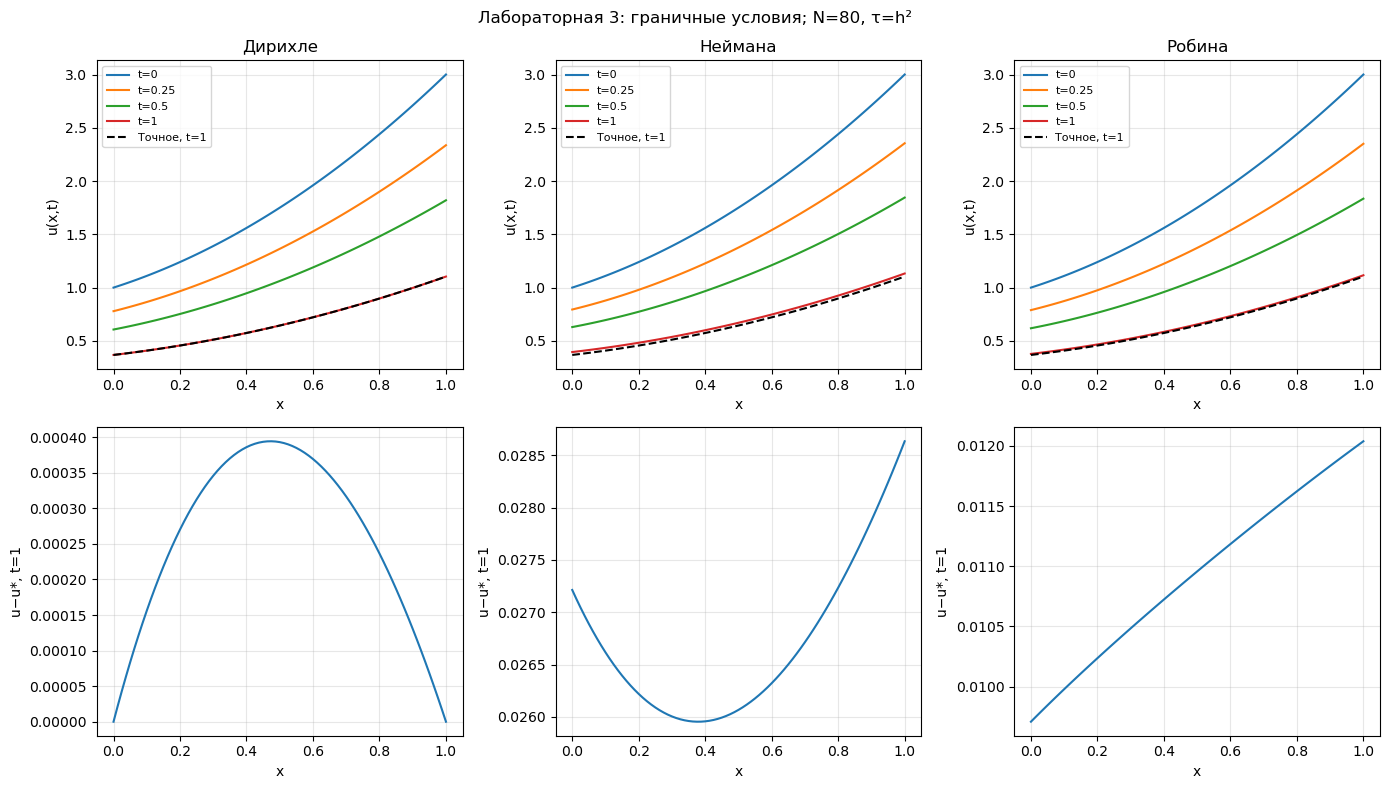

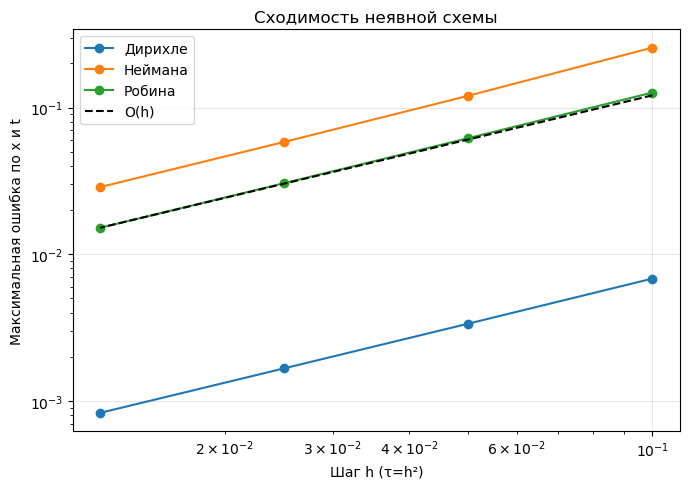

In [4]:
fig, ax = plt.subplots(2,3,figsize=(14,8))
for k,(x,t,u,exact) in enumerate(solutions):
    for time in [0.,0.25,0.5,1.]:
        j = round(time/(t[1]-t[0])); ax[0,k].plot(x,u[j],label=f't={time:g}')
    ax[0,k].plot(x,exact[-1],'k--',label='Точное, t=1'); ax[0,k].set(title=names[k],xlabel='x',ylabel='u(x,t)')
    ax[1,k].plot(x,u[-1]-exact[-1]); ax[1,k].set(xlabel='x',ylabel='u−u*, t=1')
    ax[0,k].legend(fontsize=8)
for axis in ax.flat: axis.grid(alpha=0.3)
fig.suptitle('Лабораторная 3: граничные условия; N=80, τ=h²')
fig.tight_layout(); fig.savefig(out/'solution.png',dpi=150)
fig2, axis = plt.subplots(figsize=(7,5))
for kind,name in enumerate(names,1):
    rows = convergence[convergence[:,0] == kind]; axis.loglog(rows[:,3],rows[:,5],'o-',label=name)
axis.loglog(rows[:,3],rows[-1,5]*rows[:,3]/rows[-1,3],'k--',label='O(h)')
axis.set(xlabel='Шаг h (τ=h²)',ylabel='Максимальная ошибка по x и t',title='Сходимость неявной схемы')
axis.legend(); axis.grid(alpha=0.3); fig2.tight_layout(); fig2.savefig(out/'convergence.png',dpi=150)
plt.show()


## Вывод

Для выбранного точного решения $u_*=e^{-t}(1+x+x^2)$ схема сходится для всех трёх типов граничных условий. При $N=80$, $M=6400$ максимальная ошибка при $t=1$ равна:

| Условия | Ошибка | Наблюдаемый порядок по максимуму на всей сетке |
|---|---:|---:|
| Дирихле | 0.0003943710 | 1.009 |
| Неймана | 0.0286334001 | 1.023 |
| Робина | 0.0120377258 | 1.010 |

Порядок близок к первому, что соответствует односторонним разностям переноса и граничных производных. Максимальная граничная невязка — $9.15\cdot10^{-14}$; она характеризует решение дискретных уравнений и не равна ошибке аппроксимации непрерывной задачи.

В точке $x=0.5$, $t=1$: точное значение **0.6437890221**; Дирихле — **0.6441821940**, Неймана — **0.6698554474**, Робина — **0.6547459898**.

[Таблица значений](results/values.csv) · [Сходимость](results/convergence.csv) · [Модельные коэффициенты и источник](results/model.csv)
